# 01. Exploratory Data Analysis & Physicochemical Feature Space

**Project:** Sequence-Derived Protein Solubility Prediction in the *E. coli* eSOL Dataset  


### Overview
1. **Dataset Inspection:** Verify record counts, schema integrity, and missing-value audits on the processed eSOL tables.
2. **Biological Target Summary:** Quantify solubility distribution metrics and soluble ($\ge 50\%$) vs. insoluble ($< 50\%$) class balance.
3. **Physicochemical Feature Profiling:** Explore sequence length, molecular weight, isoelectric point ($	ext{pI}$), net charge density, and GRAVY hydropathy across solubility regimes.
4. **Feature Family Breakdown:** Audit the 499 extracted multi-scale sequence descriptors.

In [3]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

def resolve_path(*candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"None of the candidate paths exist: {candidates}")

cleaned_path = resolve_path("../data/processed/esol_cleaned.csv", "data/processed/esol_cleaned.csv", "../esol_cleaned.csv")
features_path = resolve_path("../data/processed/esol_advanced_features.csv", "data/processed/esol_advanced_features.csv", "../esol_advanced_features.csv")

df_clean = pd.read_csv(cleaned_path)
df = pd.read_csv(features_path)

print(f"Loaded Cleaned Dataset   : {cleaned_path} -> {df_clean.shape}")
print(f"Loaded Feature Matrix    : {features_path} -> {df.shape}")
print(f"Missing Target Values    : {df['Solubility (%)'].isna().sum()}")
df.head(5)

Loaded Cleaned Dataset   : ../data/processed/esol_cleaned.csv -> (2642, 12)
Loaded Feature Matrix    : ../data/processed/esol_advanced_features.csv -> (2642, 508)
Missing Target Values    : 0


,JW_ID,gene,locus,Solubility (%),mw_kda_reported,pi_reported,gene_product_type,description,cell_location,sequence,...,ctd_dist_g6_0,ctd_dist_g6_25,ctd_dist_g6_50,ctd_dist_g6_75,ctd_dist_g6_100,ctd_dist_g7_0,ctd_dist_g7_25,ctd_dist_g7_50,ctd_dist_g7_75,ctd_dist_g7_100
0,JW0002,thrB,thrB,32.0,33.600,6.20,e,homoserine kinase,Cytoplasmic,MVKVYAPASSANMSVGFDVLGAAVTPVDGALLGDVVTVEAAETFSL...,...,0.054839,0.222581,0.500000,0.732258,0.993548,0.216129,0.322581,0.467742,0.687097,0.958065
1,JW0003,thrC,thrC,18.0,47.056,5.71,e,threonine synthase,Cytoplasmic,MKLYNLKDHNEQVSFAQAVTQGLGKNQGLFFPHDLPEFSLTEIDEM...,...,0.016355,0.207944,0.464953,0.778037,0.969626,0.219626,0.219626,0.397196,0.439252,0.521028
2,JW0004,yaaX,yaaX,78.0,11.400,10.90,o,predicted protein,Periplasmic,MKKMQSIVLALSLVLVAPMAAQAAEITLVPSVKLQIGDRDNRGYYW...,...,0.244898,0.377551,0.469388,0.530612,0.867347,0.000000,0.000000,0.000000,0.000000,0.000000
3,JW0005,yaaA,yaaA,7.0,29.555,8.74,o,conserved protein,Cytoplasmic,MLILISPAKTLDYQSPLTTTRYTLPELLDNSQQLIHEARKLTPPQI...,...,0.042636,0.360465,0.546512,0.755814,0.988372,0.000000,0.000000,0.000000,0.000000,0.000000
4,JW0007,talB,talB,85.0,35.200,5.80,e,transaldolase B,Cytoplasmic,MTDKLTSLRQYTTVVADTGDIAAMKLYQPQDATTNPSLILNAAQIP...,...,0.006309,0.299685,0.599369,0.798107,0.990536,0.479495,0.479495,0.523659,0.523659,0.750789


### 1. Biological Target Summary & Class Balance
At the standard biochemical threshold of **$50\%$ solubility**, proteins are stratified into soluble and aggregation-prone (insoluble) cohorts.

In [4]:
sol = df["Solubility (%)"]
summary_df = pd.DataFrame({
    "Metric": [
        "Total Mapped K-12 Proteins",
        "Mean Solubility (%)",
        "Median Solubility (%)",
        "Standard Deviation (%)",
        "Min / Max Solubility (%)",
        "Soluble Cohort (>= 50%)",
        "Insoluble Cohort (< 50%)",
    ],
    "Value": [
        f"{len(df):,}",
        f"{sol.mean():.2f}%",
        f"{sol.median():.2f}%",
        f"{sol.std():.2f}%",
        f"{sol.min():.2f}% / {sol.max():.2f}%",
        f"{(sol >= 50).sum():,} ({(sol >= 50).mean()*100:.1f}%)",
        f"{(sol < 50).sum():,} ({(sol < 50).mean()*100:.1f}%)",
    ],
})
display(summary_df)

,Metric,Value
0,Total Mapped K-12 Proteins,"2,642"
1,Mean Solubility (%),49.55%
2,Median Solubility (%),44.00%
3,Standard Deviation (%),33.48%
4,Min / Max Solubility (%),0.00% / 147.00%
5,Soluble Cohort (>= 50%),"1,206 (45.6%)"
6,Insoluble Cohort (< 50%),"1,436 (54.4%)"


### 2. Multi-Scale Descriptor Inventory (499 Features)
Grouping numeric descriptors into their biochemical families confirms full coverage across global properties, residue compositions, lagged autocorrelations, and CTD descriptors.

In [5]:
exclude_cols = {
    "JW_ID", "gene", "locus", "Solubility (%)", "sequence", "Sequence",
    "accession", "description", "cell_location", "gene_product_type"
}
num_features = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

family_counts = {
    "Amino Acid Composition (aac_*)": sum(c.startswith("aac_") for c in num_features),
    "Dipeptide Composition (di_*)": sum(c.startswith("di_") for c in num_features),
    "CTD Descriptors (ctd_*)": sum(c.startswith("ctd_") for c in num_features),
    "Autocorrelations (autocorr_*)": sum(c.startswith("autocorr_") for c in num_features),
    "Global & Physicochemical Summaries": sum(
        not c.startswith(("aac_", "di_", "ctd_", "autocorr_")) for c in num_features
    ),
}

family_df = pd.DataFrame(
    list(family_counts.items()), columns=["Feature Family", "Descriptor Count"]
)
family_df.loc[len(family_df)] = ["Total Model Predictors", sum(family_counts.values())]
display(family_df)

,Feature Family,Descriptor Count
0,Amino Acid Composition (aac_*),20
1,Dipeptide Composition (di_*),400
2,CTD Descriptors (ctd_*),42
3,Autocorrelations (autocorr_*),30
4,Global & Physicochemical Summaries,7
5,Total Model Predictors,499


### 3. Physicochemical Property Stratification by Solubility Regime
Comparing core biophysical attributes between **Soluble ($\ge 50\%$)** and **Insoluble ($< 50\%$)** proteins highlights clear structural trends:
* **Sequence Length & Molecular Weight:** Shorter polypeptides exhibit substantially higher soluble expression rates.
* **Net Charge Density:** Higher net electrostatic charge prevents intermolecular hydrophobic aggregation.

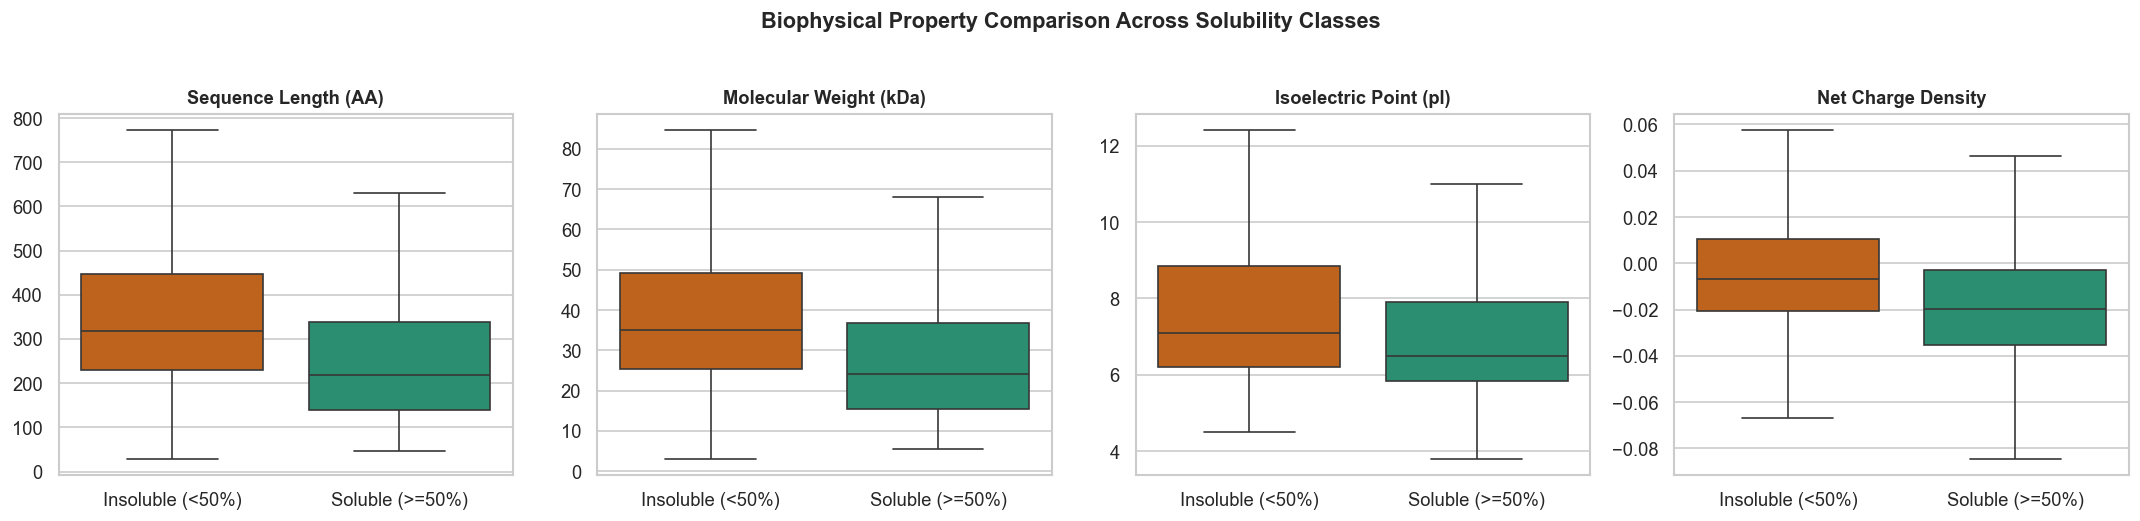

In [6]:
df_plot = df.copy()
df_plot["Solubility Class"] = np.where(df_plot["Solubility (%)"] >= 50, "Soluble (>=50%)", "Insoluble (<50%)")

candidate_props = [
    ("seq_length", "Sequence Length (AA)"),
    ("mw_kda_reported", "Molecular Weight (kDa)"),
    ("pi_reported", "Isoelectric Point (pI)"),
    ("net_charge_density", "Net Charge Density"),
]
available_props = [(col, label) for col, label in candidate_props if col in df_plot.columns]

fig, axes = plt.subplots(1, len(available_props), figsize=(4.5 * len(available_props), 4.2))
if len(available_props) == 1:
    axes = [axes]

for ax, (col, label) in zip(axes, available_props):
    sns.boxplot(
        data=df_plot,
        x="Solubility Class",
        y=col,
        ax=ax,
        palette=["#d95f02", "#1b9e77"],
        showfliers=False,
    )
    ax.set_title(label, fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Biophysical Property Comparison Across Solubility Classes", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()

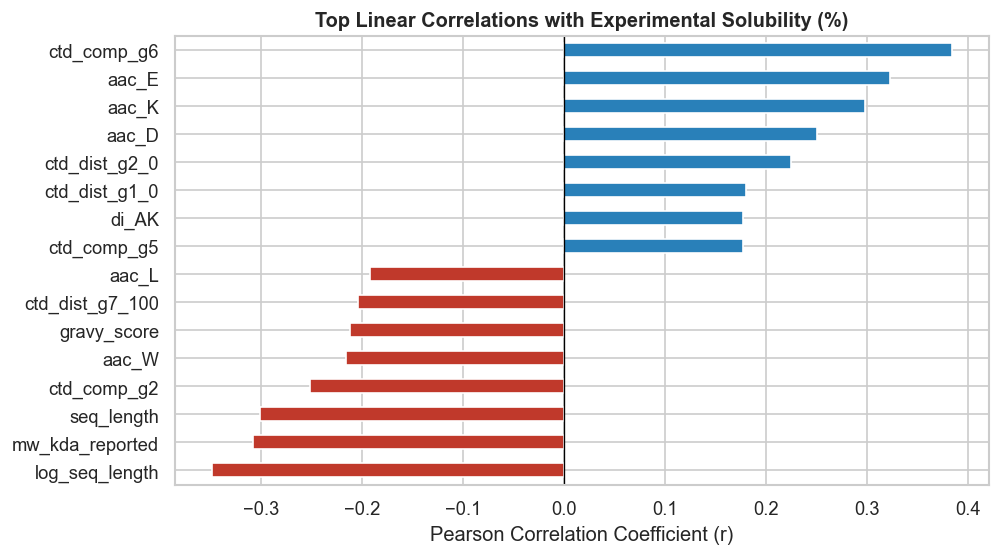

In [7]:
# Top 15 Correlated Features with Experimental Solubility (%)
corrs = df[num_features].corrwith(df["Solubility (%)"]).dropna()
top_pos = corrs.nlargest(8)
top_neg = corrs.nsmallest(8)
top_corr = pd.concat([top_neg, top_pos]).sort_values()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = ["#c0392b" if v < 0 else "#2980b9" for v in top_corr.values]
top_corr.plot(kind="barh", color=colors, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top Linear Correlations with Experimental Solubility (%)", fontsize=12, fontweight="bold")
ax.set_xlabel("Pearson Correlation Coefficient (r)")
plt.tight_layout()
plt.show()